In [1]:
from google.colab import files

uploaded = files.upload() #ap24110010670

Saving train.csv to train.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv("/content/train.csv")

train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
train.shape

(891, 12)

In [4]:
train.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [5]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
train.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [7]:
from sklearn import preprocessing

label_encoder = preprocessing.LabelEncoder()

encoded_sex = label_encoder.fit_transform(train["Sex"])

encoded_sex

array([1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1,
       0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0,
       0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1,
       0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0,
       1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1,
       0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1,
       0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0,
       1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1,
       0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0,

In [8]:
from sklearn import tree

tree_model = tree.DecisionTreeClassifier(
    random_state=1
)

tree_model.fit(
    pd.DataFrame(encoded_sex),
    train["Survived"]
)

DecisionTreeClassifier(random_state=1)

In [9]:
tree_model.score(
    pd.DataFrame(encoded_sex),
    train["Survived"]
)

0.7867564534231201

In [10]:
from sklearn.model_selection import KFold

kf = KFold(
    n_splits=10,
    shuffle=True,
    random_state=12
)

kf.get_n_splits(train)

10

In [11]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    tree_model,
    pd.DataFrame(encoded_sex),
    train["Survived"],
    cv=kf
)

scores

array([0.76666667, 0.73033708, 0.7752809 , 0.74157303, 0.79775281,
       0.80898876, 0.78651685, 0.80898876, 0.85393258, 0.79775281])

In [12]:
scores.mean()

np.float64(0.7867790262172285)

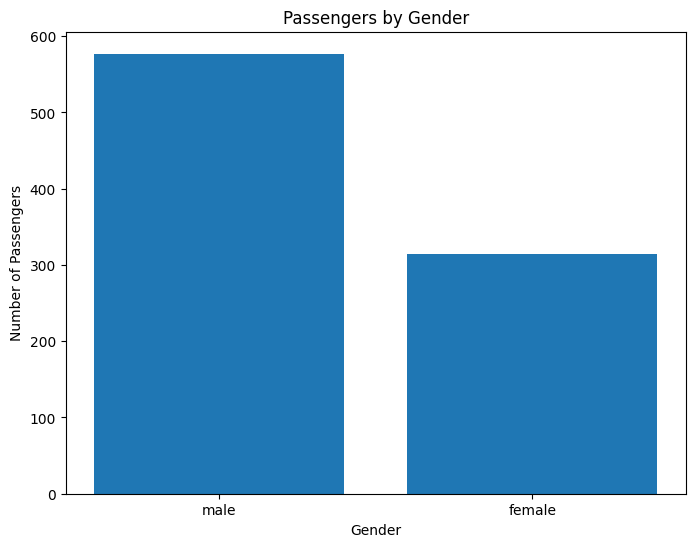

In [13]:
gender_count = train["Sex"].value_counts()

plt.figure(figsize=(8,6))

plt.bar(
    gender_count.index,
    gender_count.values
)

plt.title("Passengers by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

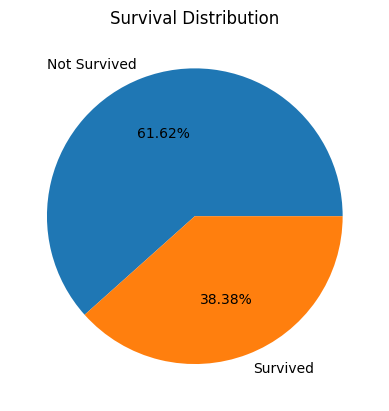

In [14]:
survival_count = train["Survived"].value_counts()

plt.pie(
    survival_count,
    labels=["Not Survived", "Survived"],
    autopct="%.2f%%"
)

plt.title("Survival Distribution")

plt.show()

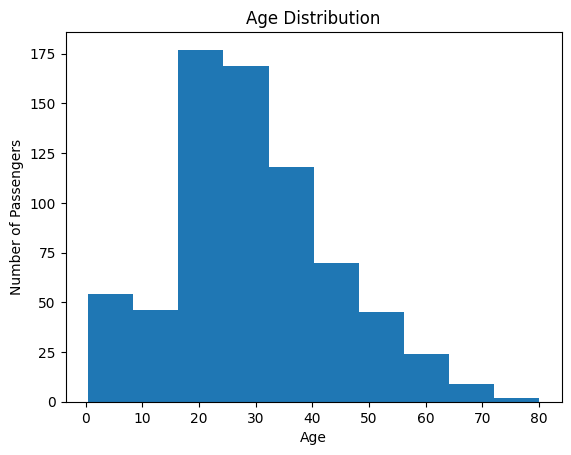

In [15]:
plt.hist(train["Age"].dropna(), bins=10)

plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.title("Age Distribution")

plt.show()

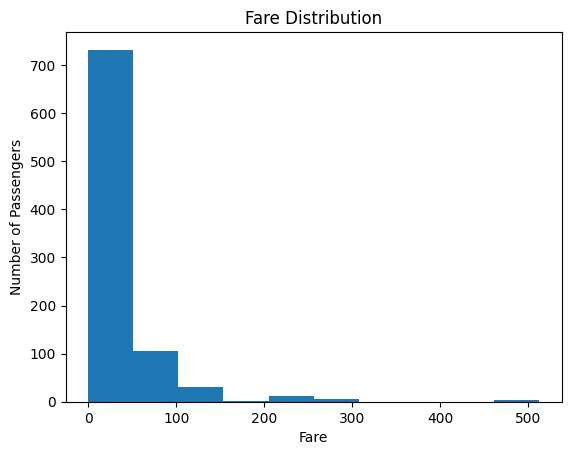

In [16]:
plt.hist(train["Fare"], bins=10)

plt.xlabel("Fare")
plt.ylabel("Number of Passengers")
plt.title("Fare Distribution")

plt.show()

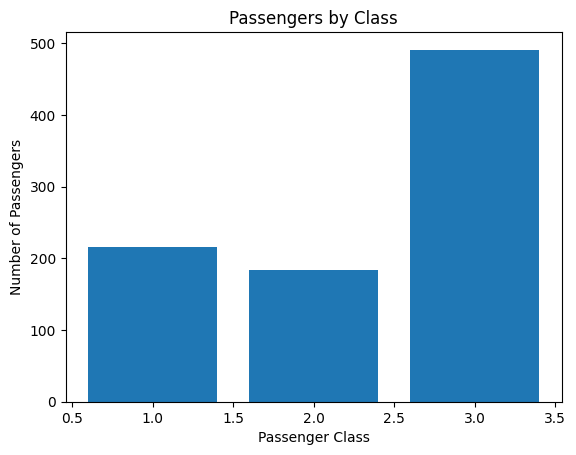

In [17]:
class_count = train["Pclass"].value_counts().sort_index()

plt.bar(
    class_count.index,
    class_count.values
)

plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.title("Passengers by Class")

plt.show()

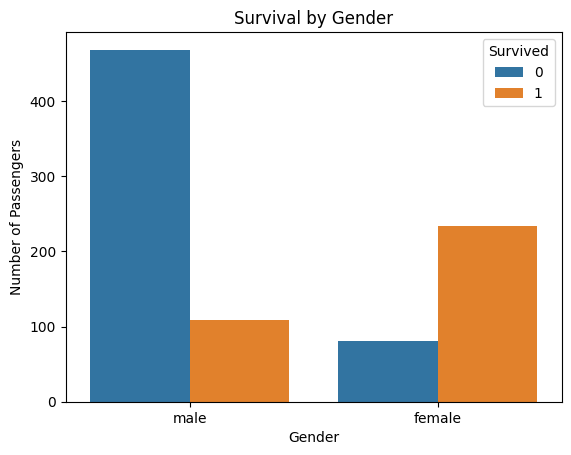

In [18]:
sns.countplot(
    x="Sex",
    hue="Survived",
    data=train
)

plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

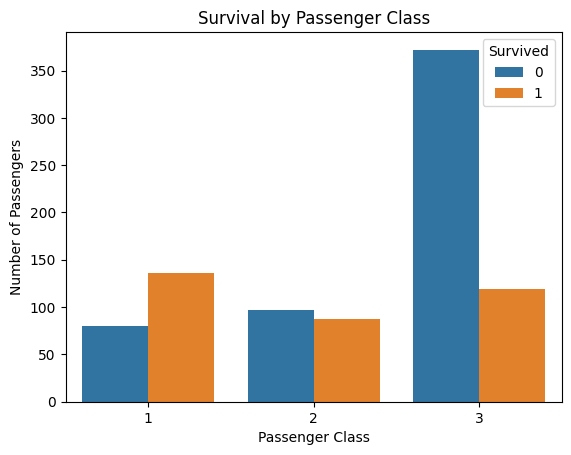

In [19]:
sns.countplot(
    x="Pclass",
    hue="Survived",
    data=train
)

plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.show()

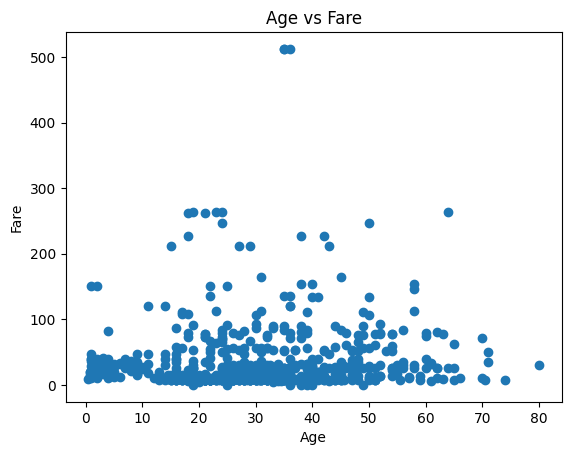

In [20]:
plt.scatter(
    train["Age"],
    train["Fare"]
)

plt.xlabel("Age")
plt.ylabel("Fare")
plt.title("Age vs Fare")

plt.show()